# 51. Lagged cross-coin residual downside stress and spectral early warning (BTC spot)

I test whether lagged, BTC-adjusted altcoin downside stress adds pre-onset information beyond (a) the frozen M0 volatility and sell-flow baseline and (b) an identical HGB with the BTC spectral feature `z_hs`.

- Data and periods: existing spot parquets only, namely the BTC spot cache and four altcoin spot caches from `multicoin_shared_budget_v1/cache` (no futures); 2021 training, unlabeled 2022 calibration, development January 2023 to April 2026.
- Features (fixed): the 60-minute alt return over `[t-75, t-15]` minus `alpha_2021 + beta_2021 × r_BTC`, standardized by its 2021 residual SD; `residual_downside = mean(max(0,-z_resid))` and `residual_breadth = fraction(z_resid ≤ -1)` over the four alts, which require at least three valid coins at each minute and use no forward filling. I estimate beta, center and scale on 2021 only. The 15-minute lag uses no information after `t−15`, but does not by itself show that altcoin stress causes BTC declines.
- Models: I first reproduce the notebook 47 counts (M0 22/800; HGB Base 13/800 breach-anchored and 9/800 onset-anchored; HGB+HS 12/800 and 16/800). I then train and evaluate five arms on the identical common-support mask with the same 2021 breach label and 2022 budget calibration: `M0`, `HGB_Base`, `HGB_HS`, `HGB_Stress` and `HGB_HS_Stress`, which adds a fixed `z_hs × residual-downside-stress` interaction.
- Endpoints: 4-hour onset-anchored catches 30–240 minutes before onset and the 4-hour breach-anchored pre-onset catches of notebook 47, at 20 alerts per month, 240 per year and a 240-minute cooldown. Neither is a new confirmatory primary test, since I selected the onset anchor after historical inspection; 24-hour checks, pre-onset AUC and within-volatility-decile AUC are descriptive.
- Status: exploratory and post hoc; I have viewed the 2023–2026 events extensively, so I select no winner and report no independent p-value, and I leave the registered December 2026 to November 2027 prospective interval and the 2018–2020 tests unchanged. I save all arms, training coverage and parameters, paired event results, monthly budget use and source hashes.
- Results folder: `crosscoin_leading_stress_spectral_v1`.

In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from IPython.display import display
try:
    import pyarrow
except ImportError:
    subprocess.check_call([sys.executable, '-m','pip','-q','install','pyarrow'])
try:
    from numba import njit
except ImportError:
    subprocess.check_call([sys.executable,'-m','pip','-q','install','numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Outside Colab: point ROOT to mounted data manually.')
ROOT=Path('/content/drive/MyDrive/btc_lead_cost_results_77months_spot')
BTC_CACHE=ROOT/'cache'
ALT_CACHE=ROOT/'multicoin_shared_budget_v1'/'cache'
OUT=ROOT/'crosscoin_leading_stress_spectral_v1'
OUT.mkdir(parents=True,exist_ok=True)
NS=60*10**9
T0=pd.Timestamp('2021-01-01',tz='UTC').value
T1=pd.Timestamp('2022-01-01',tz='UTC').value
T2=pd.Timestamp('2023-01-01',tz='UTC').value
E0=T2
E1=pd.Timestamp('2026-05-01',tz='UTC').value
LEAD_MIN=30;LEAD_MAX=240;COOLDOWN=240;BUDGET_MONTH=20;BUDGET_YEAR=240
ALT_SYMBOLS=['ETHUSDT','SOLUSDT','DOGEUSDT','AVAXUSDT']
ALT_LAG=15;RETURN_WINDOW=60;MIN_ALTS=3;RESID_BREADTH_Z=-1.0;SPECTRAL_CLIP=6.0
HGB_PARAMS=dict(max_iter=100,max_leaf_nodes=7,learning_rate=0.05,
                min_samples_leaf=100,l2_regularization=5.0,max_bins=127,
                early_stopping=False,random_state=20261147)
SPEC={'notebook':51,'status':'exploratory_posthoc_not_validation',
 'coin_cache': 'btc_lead_cost_results_77months_spot/multicoin_shared_budget_v1/cache',
 'venue':'spot','coins':ALT_SYMBOLS,'return_minutes':RETURN_WINDOW,
 'lag_minutes':ALT_LAG,'min_valid_altcoins':MIN_ALTS,
 'btc_beta_alpha_scale_fit':'2021_only','residual_breadth_z_threshold':RESID_BREADTH_Z,
 'train':'2021 identical complete-case shared mask; breach label',
 '2022':'unlabeled 20/month 240/year threshold calibration',
 'development':'2023-01 through 2026-04 (repeatedly inspected)',
 'lead_minutes':[LEAD_MIN,LEAD_MAX], 'cooldown_minutes':COOLDOWN,
 'hgb_params':HGB_PARAMS,
 'fair_arms':['M0','HGB_Base','HGB_HS','HGB_Stress','HGB_HS_Stress'],
 'new_features':['residual_downside','residual_breadth'],
 'interaction':'clip(z_hs,-6,6)*clip(residual_downside,0,6)',
 'onset_anchor':'exploratory posthoc after repeated inspection',
 'original_breach_anchor':'report alongside onset; 47 primary previously negative',
 'no_claim_of_independent_validation':True,
 'do_not_use_existing_osf_prospective_period':'2026-12 through 2027-11'}
(OUT/'51_SPEC.json').write_text(json.dumps(SPEC,indent=2))
print('Output folder',OUT)

Mounted at /content/drive
Output folder /content/drive/MyDrive/btc_lead_cost_results_77months_spot/crosscoin_leading_stress_spectral_v1


## A. Reconstruction of the BTC-only study before the alt features

I take the functions and labels from notebook 47.

In [2]:
for p in [BTC_CACHE/'BTCUSDT_1m_regularized.parquet', BTC_CACHE/'btc_signals_1m.parquet', BTC_CACHE/'DATA_SOURCE.json']:
    if not p.is_file():
        raise FileNotFoundError(f'Required frozen spot cache missing: {p}')
source = json.loads((BTC_CACHE/'DATA_SOURCE.json').read_text())
assert source.get('venue')=='spot', 'The cache must be BTC SPOT; no futures substitute.'
px = pd.read_parquet(BTC_CACHE/'BTCUSDT_1m_regularized.parquet').sort_index()
sg = pd.read_parquet(BTC_CACHE/'btc_signals_1m.parquet', columns=['z_vol','tsr','z_hs']).sort_index()
for d in (px, sg):
    assert isinstance(d.index, pd.DatetimeIndex) and d.index.tz is not None
    d.index = d.index.tz_convert('UTC')
assert px.index.equals(sg.index), 'Price/signal minute indexes differ'
T = px.index.asi8
assert np.all(np.diff(T)==NS), 'Index is not a complete one-minute grid'
close = px.close.to_numpy(dtype=float)
volume = px.volume.to_numpy(dtype=float)
X = sg[['z_vol','tsr','z_hs']].to_numpy(dtype=float)
valid = (np.isfinite(close)&(close>0)&np.isfinite(volume)&(volume>0)&
         np.isfinite(X).all(axis=1)&(X[:,1]>=0)&(X[:,1]<=1))
print('rows',len(T),'train valid',int((valid&(T>=T0)&(T<T1)).sum()),'eval valid',int((valid&(T>=E0)&(T<E1)).sum()))

def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory: continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi],'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    if not rows: raise RuntimeError('Event catalog empty')
    return pd.DataFrame(rows)

CAT = {h:price_only_catalog(close,volume,px.index,H=h) for h in (240,1440)}
EVAL = {h:CAT[h].loc[(CAT[h].breach_utc.astype('int64')>=E0+LEAD_MAX*NS)&
                             (CAT[h].breach_utc.astype('int64')<E1)].copy().reset_index(drop=True)
        for h in (240,1440)}
# Onset-anchored evaluation needs a complete onset-240 ... onset-30 window.
EVAL_ON = {h: EVAL[h].loc[EVAL[h].onset_1pct_utc.astype('int64') >= E0 + LEAD_MAX*NS].reset_index(drop=True)
           for h in (240,1440)}
# Mandatory guard against the reference 4-hour development event count
assert len(EVAL[240])==83, f'Expected 83 development events at H=240, found {len(EVAL[240])}'
assert len(EVAL[1440])==218, f'Expected 218 events at H=1440, found {len(EVAL[1440])}'
# Optional: exact timestamp comparison with notebook 2
ref = ROOT/'event_definition_eligibility_audit'/'price_only_event_catalog.csv'
if ref.is_file():
    q = pd.read_csv(ref)
    for c in ('peak_utc','onset_1pct_utc','breach_utc','confirmed_utc'):
        a = pd.to_datetime(q[c],utc=True).astype('int64').to_numpy()
        b = CAT[240][c].astype('int64').to_numpy()
        assert np.array_equal(a,b), f'Notebook 2 mismatch for {c}'
    print('PASS: notebook-2 event timestamps reproduced.')

# Labels from the next qualifying event timestamp (same searchsorted convention as notebook 41).
def future_label(T, events_ns):
    z=np.sort(np.asarray(events_ns,dtype=np.int64))
    positions=np.searchsorted(z,T+LEAD_MIN*NS,side='left')
    y=np.zeros(len(T),dtype=np.int8)
    good=positions<len(z)
    y[good]=(z[positions[good]]<=T[good]+LEAD_MAX*NS).astype(np.int8)
    return y

cat4=CAT[240]
y_breach = future_label(T,cat4.breach_utc.astype('int64').to_numpy())
y_onset = future_label(T,cat4.onset_1pct_utc.astype('int64').to_numpy())
# No retrospective classification rule is used as a runtime signal. During onset training,
# remove confirmed-event in-progress minutes from the negative training examples.
in_progress = np.zeros(len(T),bool)
for e in cat4.itertuples(index=False):
    a=np.searchsorted(T,e.onset_1pct_utc.value,'left')
    b=np.searchsorted(T,e.confirmed_utc.value,'right')
    in_progress[a:b]=True
TRAIN = valid &(T>=T0)&(T<T1-(LEAD_MAX+5)*NS)
TRAIN_ONSET = TRAIN & ~in_progress
CAL = valid &(T>=T1)&(T<T2)
DEV = valid &(T>=E0)&(T<E1-(LEAD_MAX+5)*NS)
print('2021 breach positive minutes:',int(y_breach[TRAIN].sum()))
print('2021 onset positive minutes:',int(y_onset[TRAIN_ONSET].sum()))
if not (y_breach[TRAIN].sum()>50 and y_onset[TRAIN_ONSET].sum()>50):
    raise RuntimeError('Insufficient training positives: inspect event labels and cache.')

rows 3329280 train valid 524332 eval valid 1750857
PASS: notebook-2 event timestamps reproduced.
2021 breach positive minutes: 18779
2021 onset positive minutes: 18771


## B. Refit of the notebook 47 M0 and HGB pair against the notebook 47/49 outcomes

Here I refit the notebook 47 M0 and HGB pair without the alt common-support mask and reproduce the notebook 47/49 outcomes; the common-support fit follows in section D.

In [3]:
# Baseline algorithms and labels as in notebook 47.
def fixed_hgb():
    return HistGradientBoostingClassifier(**HGB_PARAMS)

def balanced_weights(y):
    y=np.asarray(y,dtype=np.int8)
    n1=int(np.sum(y));n0=int(len(y)-n1)
    if n1<50 or n0<=n1: raise RuntimeError('Insufficient/invalid 2021 training classes')
    return np.where(y==1,len(y)/(2*n1),len(y)/(2*n0)).astype(float)

w0=balanced_weights(y_breach[TRAIN]);
M0_orig=make_pipeline(StandardScaler(),LogisticRegression(
    C=.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
M0_orig.fit(X[TRAIN,:2],y_breach[TRAIN])
HGB_Base_orig=fixed_hgb().fit(X[TRAIN,:2],y_breach[TRAIN],sample_weight=w0)
HGB_HS_orig=fixed_hgb().fit(X[TRAIN],y_breach[TRAIN],sample_weight=w0)

frozen=ROOT/'methods_definitions_v1'/'METHODS_FROZEN.json'
if frozen.is_file():
    cfg=json.loads(frozen.read_text())['configs']['M0_VF_logit|4pct']
    assert np.allclose(M0_orig[-1].coef_.ravel(),cfg['coef'],rtol=1e-6,atol=1e-9)
    assert np.isclose(M0_orig[-1].intercept_[0],cfg['intercept'],rtol=1e-6,atol=1e-9)
    print('PASS frozen M0 coefficient guard')
else:
    print('Warning: no frozen M0 model config; the exact alert guards still apply')

PASS frozen M0 coefficient guard


In [4]:
@njit(cache=False)
def calendar_core(t,elig,years,months,B,cap,cooldown_ns):
    out=np.empty(len(t),dtype=np.int64)
    n=0; month_count=0; year_count=0; last_m=-1; last_y=-1; last=-(2**62)
    for i in range(len(t)):
        if not elig[i]: continue
        yr=years[i]; mo=months[i]; ti=t[i]
        if yr!=last_y: year_count=0; last_y=yr
        if mo!=last_m: month_count=0; last_m=mo
        if month_count>=cap or year_count>=B or ti-last<cooldown_ns: continue
        out[n]=ti;n+=1;month_count+=1;year_count+=1;last=ti
    return out[:n].copy()

def scheduler(time_ns,score,threshold):
    tm=pd.to_datetime(time_ns,utc=True)
    yrs=np.asarray(tm.year,dtype=np.int64)
    months=np.asarray(tm.year*12+tm.month,dtype=np.int64)
    e=np.asarray(np.isfinite(score)&(score>=threshold),dtype=np.bool_)
    return calendar_core(np.asarray(time_ns,np.int64),e,yrs,months,BUDGET_YEAR,BUDGET_MONTH,COOLDOWN*NS)

def score_grid(sc):
    Q=np.unique(np.r_[0.,np.linspace(.10,.995,33),.997,.999,.9999,1.])
    return np.unique(np.r_[np.nextafter(sc.min(),-np.inf),np.quantile(sc,Q),np.nextafter(sc.max(),np.inf)])

def calibrate(time_ns,sc):
    rows=[]
    for th in score_grid(sc):
        count=len(scheduler(time_ns,sc,th))
        rows.append((float(th),count,int(np.count_nonzero(sc>=th))))
    d=pd.DataFrame(rows,columns=['threshold','cal_alerts','raw_candidates'])
    row=d[d.cal_alerts==d.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(row.threshold),int(row.cal_alerts),d

In [5]:
def event_catches(events, alerts, anchor='breach'):
    alert=np.asarray(alerts,dtype=np.int64)
    rows=[]
    for e in events.itertuples(index=False):
        on=e.onset_1pct_utc.value;b=e.breach_utc.value
        anchor_ns=on if anchor=='onset' else b
        lo=anchor_ns-LEAD_MAX*NS; hi=anchor_ns-LEAD_MIN*NS
        l=np.searchsorted(alert,lo,side='left')
        r=np.searchsorted(alert,hi,side='right')
        eligible=alert[l:r]
        good=eligible[eligible<on]
        rows.append((e.event_id,len(good)>0,(on-int(good[0]))/NS if len(good) else np.nan))
    return pd.DataFrame(rows,columns=['event_id','hit','lead_to_onset_minutes'])

In [6]:
P_ORIG={};A_ORIG={};C_ORIG={}
T_CAL_ORIG=T[CAL];T_DEV_ORIG=T[DEV]
for name,model,features in [
    ('M0',M0_orig,[0,1]),('HGB_Base',HGB_Base_orig,[0,1]),('HGB_HS',HGB_HS_orig,[0,1,2])]:
    def scores_on(mask):
        idx=np.flatnonzero(mask)
        arr=np.empty(len(idx),dtype=float)
        for chunk in range(0,len(idx),160000):
            sub=idx[chunk:chunk+160000]
            arr[chunk:chunk+len(sub)]=model.predict_proba(X[sub][:,features])[:,1]
        return arr
    s_cal=scores_on(CAL);s_dev=scores_on(DEV)
    thr,ncal,_=calibrate(T_CAL_ORIG,s_cal)
    alerts=scheduler(T_DEV_ORIG,s_dev,thr)
    C_ORIG[name]=(int(ncal),float(thr));A_ORIG[name]=alerts
    P_ORIG[name]={
        'breach':int(event_catches(EVAL[240],alerts,'breach').hit.sum()),
        'onset':int(event_catches(EVAL_ON[240],alerts,'onset').hit.sum()),
        'alerts':len(alerts)}
    print(name,'2022 alerts',ncal,'development',P_ORIG[name])
ORIG_EXPECT={'M0':{'breach':22,'onset':15,'alerts':800},
             'HGB_Base':{'breach':13,'onset':9,'alerts':800},
             'HGB_HS':{'breach':12,'onset':16,'alerts':800}}
assert P_ORIG==ORIG_EXPECT,f'Notebook 47/49 baseline mismatch: {P_ORIG}'
assert all(v[0]==240 for v in C_ORIG.values())
print('PASS exact 47/49 model-reproduction guards')
(OUT/'51_0_original_reproduction.json').write_text(json.dumps({'models':P_ORIG,'calibration':C_ORIG},indent=2))

M0 2022 alerts 240 development {'breach': 22, 'onset': 15, 'alerts': 800}
HGB_Base 2022 alerts 240 development {'breach': 13, 'onset': 9, 'alerts': 800}
HGB_HS 2022 alerts 240 development {'breach': 12, 'onset': 16, 'alerts': 800}
PASS exact 47/49 model-reproduction guards


461

## C. Lagged cross-coin residual-stress inputs (2021 normalization only)

For each alt and for BTC I compare the close at `t−15` with the close at `t−75`, require every one-minute close in between and use no forward fill. I fit one BTC-return beta and intercept and one residual scale per alt on 2021 only and require at least three of the fixed four coins at each minute.

In [7]:
required=[ALT_CACHE/f'{s}_1m.parquet' for s in ALT_SYMBOLS]
missing=[str(p) for p in required if not p.is_file()]
if missing:
    raise FileNotFoundError('Missing spot altcoin caches (futures data are not a substitute): '+repr(missing))

def sha256_file(path, chunk_size=16*1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            b=f.read(chunk_size)
            if not b: break
            h.update(b)
    return h.hexdigest()

source_manifest={
    'BTC_prices':sha256_file(BTC_CACHE/'BTCUSDT_1m_regularized.parquet'),
    'BTC_signals':sha256_file(BTC_CACHE/'btc_signals_1m.parquet')}

def alt_close_on_btc_grid(path, btc_index):
    # Robust to a UTC DatetimeIndex or standard Binance open_time/time column.
    frame=pd.read_parquet(path)
    cols={str(k).lower():k for k in frame.columns}
    cp=next((cols[k] for k in ('close','close_price','closing_price') if k in cols),None)
    if cp is None:
        raise ValueError(f'{path.name} lacks a close price column. Columns={frame.columns.tolist()}')
    if isinstance(frame.index,pd.DatetimeIndex):
        idx=pd.DatetimeIndex(frame.index)
        if idx.tz is None:
            # Binance stored UTC; reject ambiguous nonstandard dates when they do not align.
            idx=idx.tz_localize('UTC')
        else:
            idx=idx.tz_convert('UTC')
    else:
        tc=next((cols[k] for k in ('open_time','timestamp','time','datetime','date','utc','open_timestamp') if k in cols),None)
        if tc is None:
            raise ValueError(f'{path.name}: no datetime index or recognized UTC time column; columns={frame.columns.tolist()}')
        ts=frame[tc]
        if pd.api.types.is_numeric_dtype(ts):
            val=pd.to_numeric(ts,errors='coerce'); mag=val.dropna().abs().median()
            unit='ns' if mag>=1e17 else ('us' if mag>=1e14 else ('ms' if mag>=1e11 else 's'))
            idx=pd.to_datetime(ts,unit=unit,utc=True,errors='coerce')
        else:
            idx=pd.to_datetime(ts,utc=True,errors='coerce')
    x=pd.Series(pd.to_numeric(frame[cp],errors='coerce').to_numpy(dtype=np.float64),index=idx)
    del frame
    if x.index.hasnans: x=x.loc[~x.index.isna()]
    if x.index.has_duplicates:
        # Duplicates must be exact, or the source is ambiguous: do not choose by hindsight.
        duplicated=x.index[x.index.duplicated(keep=False)]
        if x.loc[duplicated].groupby(level=0).nunique(dropna=False).max()>1:
            raise ValueError(f'{path.name}: conflicting duplicated candle timestamps')
        x=x.loc[~x.index.duplicated(keep='first')]
    if not x.index.is_monotonic_increasing: x=x.sort_index()
    if len(x) and np.any(x.index.asi8 % NS):
        raise ValueError(f'{path.name}: observed timestamps not aligned to one-minute UTC grid')
    x=x.where(x>0).reindex(btc_index).astype(np.float64)
    return x

# Leakage diagnostic: t-15 to t-75 has no overlap with (t,t+240].
assert ALT_LAG>=1 and RETURN_WINDOW>=1 and ALT_LAG+RETURN_WINDOW==75
# The BTC closes are already on a continuous 1-minute grid.
btc_s=pd.Series(np.where(np.isfinite(close)&(close>0),close,np.nan),index=px.index)
btc_lp=np.log(btc_s)
btc_r=(btc_lp.shift(ALT_LAG)-btc_lp.shift(ALT_LAG+RETURN_WINDOW)).to_numpy(dtype=np.float64)
btc_avail=(btc_s.notna().rolling(ALT_LAG+RETURN_WINDOW+1,min_periods=ALT_LAG+RETURN_WINDOW+1).sum().to_numpy()==ALT_LAG+RETURN_WINDOW+1)

# Store per-coin standardized residual arrays as float32, keeping memory moderate.
alt_z={};betas=[];coverage=[]
for sym,path in zip(ALT_SYMBOLS,required):
    s=alt_close_on_btc_grid(path,px.index)
    source_manifest[sym+'_price']=sha256_file(path)
    lp=np.log(s)
    ar=(lp.shift(ALT_LAG)-lp.shift(ALT_LAG+RETURN_WINDOW)).to_numpy(dtype=np.float64)
    # Need observations throughout the 60-minute *return interval*, not across future minutes.
    # At time t the last used price is t-15 (no data needed from t-14..t).
    complete=(s.notna().rolling(RETURN_WINDOW+1,min_periods=RETURN_WINDOW+1).sum().shift(ALT_LAG).to_numpy()==RETURN_WINDOW+1)
    ok=complete & np.isfinite(ar)&np.isfinite(btc_r)&btc_avail
    fit=ok&(T>=T0)&(T<T1)
    if fit.sum()<100_000:
        raise RuntimeError(f'{sym}: too few 2021 observed valid 60m lagged returns ({fit.sum()})')
    a=ar[fit];b=btc_r[fit]
    beta=float(np.cov(a,b,bias=True)[0,1]/np.var(b))
    alpha=float(np.mean(a)-beta*np.mean(b))
    resid=ar-(alpha+beta*btc_r)
    resid[~ok]=np.nan
    sigma=float(np.std(resid[fit],ddof=0))
    if not sigma>1e-8: raise RuntimeError(f'{sym}: residual volatility degeneracy')
    z=(resid/sigma).astype(np.float32)
    alt_z[sym]=z
    betas.append({'symbol':sym,'alpha_2021':alpha,'beta_2021':beta,'resid_sigma_2021':sigma,
                  'train_minutes':int(fit.sum()),'train_mean_std_resid':float(np.mean(resid[fit]/sigma))})
    coverage.append({'symbol':sym,'train_2021_coverage_pct':float(100*np.mean(ok[(T>=T0)&(T<T1)])),
                     'cal_2022_coverage_pct':float(100*np.mean(ok[(T>=T1)&(T<T2)])),
                     'dev_coverage_pct':float(100*np.mean(ok[(T>=E0)&(T<E1)]))})
    print(sym,'2021 beta',round(beta,3),'training availability',int(fit.sum()))
    del s,lp,ar,complete,resid,z
    gc.collect()

# Fixed four-coin aggregation. NaNs never turn into false signs in the denominator.
zmat=np.column_stack([alt_z[s] for s in ALT_SYMBOLS]);valid_coins=np.isfinite(zmat)
ncoins=valid_coins.sum(axis=1)
with np.errstate(invalid='ignore',divide='ignore'):
    # Use sum/count rather than nanmean to avoid warnings for unobserved minutes.
    downside=(np.nansum(np.where(valid_coins,np.maximum(0.,-zmat),np.nan),axis=1)/np.maximum(ncoins,1)).astype(np.float32)
    breadth=(np.sum(valid_coins & (zmat<=RESID_BREADTH_Z),axis=1)/np.maximum(ncoins,1)).astype(np.float32)
common_alt=ncoins>=MIN_ALTS
downside[~common_alt]=np.nan;breadth[~common_alt]=np.nan
assert np.nanmin(downside)>=0 and np.nanmax(breadth)<=1
X_NEW=np.column_stack([downside,breadth]).astype(np.float32)
COMMON=valid&np.isfinite(X_NEW).all(axis=1)
TRAIN_C=TRAIN&COMMON;CAL_C=CAL&COMMON;DEV_C=DEV&COMMON
COV_SUM=[]
for name,old,new in [('train_2021',TRAIN,TRAIN_C),('cal_2022',CAL,CAL_C),('dev_2023_2026Apr',DEV,DEV_C)]:
    fraction=float(new.sum()/old.sum())
    COV_SUM.append({'period':name,'btc_valid_minutes':int(old.sum()),
                    'common_support_minutes':int(new.sum()),'retained_fraction':fraction})
    print(name,f'{fraction:.2%} shared coverage ({int(new.sum())}/{int(old.sum())})')
    if fraction<.80:
        raise RuntimeError(f'{name}: common coverage below 80%; mixed-support models are not comparable')
if int(y_breach[TRAIN_C].sum())<50:raise RuntimeError('Insufficient events in common-support 2021 training')
display(pd.DataFrame(COV_SUM));display(pd.DataFrame(betas))
pd.DataFrame(betas).to_csv(OUT/'51_1_alt_2021_residual_parameters.csv',index=False)
pd.DataFrame(coverage).to_csv(OUT/'51_1_per_coin_coverage.csv',index=False)
pd.DataFrame(COV_SUM).to_csv(OUT/'51_1_common_support.csv',index=False)
(OUT/'51_SOURCE_HASHES.json').write_text(json.dumps(source_manifest,indent=2))
# Do not use a current-minute BTC price to calculate the alt return; all cross features lag by 15 minutes.
del zmat,alt_z,valid_coins,btc_lp,btc_r,btc_s,btc_avail
import gc;gc.collect()

ETHUSDT 2021 beta 1.069 training availability 524157
SOLUSDT 2021 beta 1.108 training availability 524157
DOGEUSDT 2021 beta 1.116 training availability 524157
AVAXUSDT 2021 beta 1.244 training availability 524157
train_2021 99.95% shared coverage (523823/524087)
cal_2022 100.00% shared coverage (525600/525600)
dev_2023_2026Apr 100.00% shared coverage (1750568/1750612)


,period,btc_valid_minutes,common_support_minutes,retained_fraction
0,train_2021,524087,523823,0.999496
1,cal_2022,525600,525600,1.000000
2,dev_2023_2026Apr,1750612,1750568,0.999975


,symbol,alpha_2021,beta_2021,resid_sigma_2021,train_minutes,train_mean_std_resid
0,ETHUSDT,0.000126,1.069412,0.006507,524157,2.602736e-18
1,SOLUSDT,0.000476,1.107695,0.015265,524157,-1.041094e-17
2,DOGEUSDT,0.000344,1.115733,0.022885,524157,-3.470314e-18
3,AVAXUSDT,0.000345,1.244275,0.016273,524157,2.168946e-18


0

## D. The same breach-target model family trained on common support

These controls see the same 2021 rows and can alert on the same minutes of 2022 and of 2023 to April 2026; the HGB models share fixed tree hyperparameters and weights, so the features are the only ablation. With an explicit spectral × stress product I test the conditional-stress hypothesis without changing the training target, budget or clock.

In [8]:
# Five fair common-support models. All train on identical events/masks.
zhs=np.clip(X[:,2],-SPECTRAL_CLIP,SPECTRAL_CLIP)
stress=np.clip(X_NEW[:,0],0,6)
product=(zhs*stress).astype(np.float32)
FEATURES={
 'M0':[0,1],
 'HGB_Base':[0,1],
 'HGB_HS':[0,1,2],
 'HGB_Stress':[0,1,3,4],
 'HGB_HS_Stress':[0,1,2,3,4,5]
}
# Only slice X_ALL on common-support rows; NaNs elsewhere are never supplied to estimators.
X_ALL=np.column_stack([X.astype(np.float32),X_NEW,product])
assert np.isfinite(X_ALL[TRAIN_C]).all()
w=balanced_weights(y_breach[TRAIN_C]);y=y_breach[TRAIN_C]
MODEL={}
for name in FEATURES:
    inds=FEATURES[name]
    if name=='M0':
        model=make_pipeline(StandardScaler(),LogisticRegression(
            C=.2,class_weight='balanced',max_iter=400,solver='lbfgs',random_state=17))
        model.fit(X_ALL[TRAIN_C][:,inds],y)
    else:
        model=fixed_hgb()
        model.fit(X_ALL[TRAIN_C][:,inds],y,sample_weight=w)
    MODEL[name]=model
    print('Fitted',name,'with',len(inds),'predictors; train positive labels',int(y.sum()))

def predict_mask(model,cols,mask):
    row=np.flatnonzero(mask)
    result=np.empty(len(row),dtype=np.float64)
    for k in range(0,len(row),160_000):
        sub=row[k:k+160_000]
        result[k:k+len(sub)]=model.predict_proba(X_ALL[sub][:,cols])[:,1]
    return result

T_CAL_C=T[CAL_C];T_DEV_C=T[DEV_C]
S_CAL={};S_DEV={};ALERTS={};THRESH={};N_CAL={}
for name in FEATURES:
    sc_cal=predict_mask(MODEL[name],FEATURES[name],CAL_C)
    sc_dev=predict_mask(MODEL[name],FEATURES[name],DEV_C)
    th,ncal,grid=calibrate(T_CAL_C,sc_cal)
    alert=scheduler(T_DEV_C,sc_dev,th)
    assert np.isfinite(sc_cal).all() and np.isfinite(sc_dev).all()
    THRESH[name]=th;N_CAL[name]=ncal;S_CAL[name]=sc_cal;S_DEV[name]=sc_dev;ALERTS[name]=alert
    grid.assign(model=name).to_csv(OUT/f'51_calibration_grid_{name}.csv',index=False)
    print(f'{name:18s}: calibration={ncal}, development={len(alert)}, threshold={th:.9g}')
# The shared support may change the exact notebook 47/50 catches, so I do not assert them here.
if not all(int(N_CAL[n])>=210 for n in FEATURES):
    print('Warning: one or more arms use <210/240 calibration alerts, so budget differences affect the comparison.')

Fitted M0 with 2 predictors; train positive labels 18779
Fitted HGB_Base with 2 predictors; train positive labels 18779
Fitted HGB_HS with 3 predictors; train positive labels 18779
Fitted HGB_Stress with 4 predictors; train positive labels 18779
Fitted HGB_HS_Stress with 6 predictors; train positive labels 18779
M0                : calibration=240, development=800, threshold=0.669900612
HGB_Base          : calibration=240, development=800, threshold=0.618529775
HGB_HS            : calibration=240, development=800, threshold=0.623183819
HGB_Stress        : calibration=240, development=800, threshold=0.630498519
HGB_HS_Stress     : calibration=240, development=800, threshold=0.628024961


## E. Comparison of all models at identical supported minutes

I report both the primary breach-anchored and the onset-anchored 30–240 minute endpoints, in each case with the alert before onset, plus descriptive 24-hour definitions. The event catalog is the same for all arms, and AUCs use shared support and the same 24-hour RV bins. Any confidence intervals are descriptive and post hoc, with no correction for repeated searches.

In [9]:
EVENTS=[];HITS={}
for h in (240,1440):
    for anchor in ('breach','onset'):
        ev=EVAL[h] if anchor=='breach' else EVAL_ON[h]
        for name in FEATURES:
            hit=event_catches(ev,ALERTS[name],anchor)
            HITS[(h,anchor,name)]=hit
            kk=int(hit.hit.sum());nn=len(ALERTS[name])
            EVENTS.append({'H':h,'anchor':anchor,'model':name,'events':len(ev),'alerts':nn,
                           'cal_alerts_2022':N_CAL[name],'pre_catches':kk,
                           'catches_per_100_alerts':100*kk/nn if nn else np.nan,
                           'pre_recall':kk/len(ev),
                           'median_lead_minutes':hit.lead_to_onset_minutes.median()})
EVENT_RESULTS=pd.DataFrame(EVENTS)
EVENT_RESULTS.to_csv(OUT/'51_2_all_models_event_results.csv',index=False)
display(EVENT_RESULTS)

# Pairwise event matrices let the reader see what was gained and lost, not only totals.
PAIR_NAMES=[('HGB_Base','HGB_Stress'),('HGB_HS','HGB_HS_Stress'),
            ('HGB_Stress','HGB_HS_Stress'),('HGB_Base','HGB_HS'),('M0','HGB_HS_Stress')]
MATRIX=[];PAIR=[];rng=np.random.default_rng(20261151)
for h in (240,1440):
    for anchor in ('breach','onset'):
        for name in FEATURES:
            hh=HITS[(h,anchor,name)]
            for row in hh.itertuples(index=False):
                MATRIX.append({'H':h,'anchor':anchor,'event_id':row.event_id,'model':name,
                               'hit':bool(row.hit),'lead_to_onset_min':row.lead_to_onset_minutes})
        for baseline,candidate in PAIR_NAMES:
            a=HITS[(h,anchor,baseline)].hit.to_numpy(bool)
            b=HITS[(h,anchor,candidate)].hit.to_numpy(bool)
            idx=rng.integers(0,len(a),(2000,len(a)))
            dif=(b[idx].astype(int)-a[idx].astype(int)).sum(axis=1)
            PAIR.append({'H':h,'anchor':anchor,'baseline':baseline,'candidate':candidate,
                         'base_catches':int(a.sum()),'candidate_catches':int(b.sum()),
                         'delta_catches':int(b.sum()-a.sum()),
                         'baseline_only':int((a&~b).sum()),'candidate_only':int((~a&b).sum()),
                         'event_boot_lo_descriptive':float(np.percentile(dif,2.5)),
                         'event_boot_hi_descriptive':float(np.percentile(dif,97.5)),
                         'posthoc_not_inference':True})
pd.DataFrame(MATRIX).to_csv(OUT/'51_3_event_level_all_models.csv',index=False)
PAIR_DF=pd.DataFrame(PAIR)
PAIR_DF.to_csv(OUT/'51_4_paired_event_descriptive.csv',index=False)
display(PAIR_DF.query('H==240'))

,H,anchor,model,events,alerts,cal_alerts_2022,pre_catches,catches_per_100_alerts,pre_recall,median_lead_minutes
0,240,breach,M0,83,800,240,22,2.750,0.265060,25.0
1,240,breach,HGB_Base,83,800,240,7,0.875,0.084337,71.0
2,240,breach,HGB_HS,83,800,240,14,1.750,0.168675,53.0
3,240,breach,HGB_Stress,83,800,240,19,2.375,0.228916,53.0
4,240,breach,HGB_HS_Stress,83,800,240,19,2.375,0.228916,34.0
5,240,onset,M0,83,800,240,15,1.875,0.180723,72.0
6,240,onset,HGB_Base,83,800,240,14,1.750,0.168675,131.0
7,240,onset,HGB_HS,83,800,240,15,1.875,0.180723,149.0
8,240,onset,HGB_Stress,83,800,240,17,2.125,0.204819,103.0
9,240,onset,HGB_HS_Stress,83,800,240,17,2.125,0.204819,105.0


,H,anchor,baseline,candidate,base_catches,candidate_catches,delta_catches,baseline_only,candidate_only,event_boot_lo_descriptive,event_boot_hi_descriptive,posthoc_not_inference
0,240,breach,HGB_Base,HGB_Stress,7,19,12,1,13,5.0,19.0,True
1,240,breach,HGB_HS,HGB_HS_Stress,14,19,5,2,7,-1.0,11.0,True
2,240,breach,HGB_Stress,HGB_HS_Stress,19,19,0,1,1,-3.0,3.0,True
3,240,breach,HGB_Base,HGB_HS,7,14,7,1,8,1.0,13.0,True
4,240,breach,M0,HGB_HS_Stress,22,19,-3,6,3,-9.0,3.0,True
5,240,onset,HGB_Base,HGB_Stress,14,17,3,4,7,-3.0,10.0,True
6,240,onset,HGB_HS,HGB_HS_Stress,15,17,2,4,6,-4.0,8.0,True
7,240,onset,HGB_Stress,HGB_HS_Stress,17,17,0,0,0,0.0,0.0,True
8,240,onset,HGB_Base,HGB_HS,14,15,1,2,3,-3.0,6.0,True
9,240,onset,M0,HGB_HS_Stress,15,17,2,4,6,-4.0,8.0,True


In [10]:
# AUC decomposition as in notebook 47, on the same shared-support minutes.
# COM is DEV_C intersect finite 24h BTC realized volatility.
logr=np.log(pd.Series(np.where(np.isfinite(close)&(close>0),close,np.nan))).diff()
RV=logr.rolling(1440,min_periods=720).std().to_numpy()
RV_DEV=RV[DEV_C]
KEEP=np.isfinite(RV_DEV)
T_COM=T_DEV_C[KEEP]
qs=np.quantile(RV_DEV[KEEP],np.arange(.1,1.,.1))
DEC=np.searchsorted(qs,RV_DEV[KEEP],side='right')

def encoded_breach_labels(times,events):
    b=events.breach_utc.astype('int64').to_numpy()
    o=events.onset_1pct_utc.astype('int64').to_numpy()
    ix=np.searchsorted(b,times+LEAD_MIN*NS,'left')
    enc=np.zeros(len(times),dtype=np.int8)
    ok=ix<len(b)
    active=ok.copy()
    active[ok]=b[ix[ok]]<=times[ok]+LEAD_MAX*NS
    enc[active]=np.where(times[active]<o[ix[active]],1,2)
    return enc

def safe_auc(pos,neg,sc):
    if not(pos.any() and neg.any()):return np.nan
    return float(roc_auc_score(np.r_[np.ones(pos.sum()),np.zeros(neg.sum())],
                               np.r_[sc[pos],sc[neg]]))

def weighted_within_decile(pre,neg,scores,dec):
    aucs=[];ww=[]
    for k in range(10):
        p=pre&(dec==k);n=neg&(dec==k)
        if p.any() and n.any():
            aucs.append(safe_auc(p,n,scores))
            ww.append(int(p.sum())*int(n.sum()))
    return float(np.average(aucs,weights=ww)) if ww else np.nan

AUC=[]
for h in (240,1440):
    enc=encoded_breach_labels(T_COM,EVAL[h])
    neg=enc==0;pre=enc==1;inprog=enc==2
    for name in FEATURES:
        sc=S_DEV[name][KEEP]
        auc_pre=safe_auc(pre,neg,sc)
        auc_in=safe_auc(inprog,neg,sc)
        auc_all=safe_auc(enc>0,neg,sc)
        pi=inprog.sum()/(pre.sum()+inprog.sum())
        if np.all(np.isfinite([auc_pre,auc_in,auc_all])):
            assert abs(auc_all-((1-pi)*auc_pre+pi*auc_in))<1e-8
        AUC.append({'H':h,'model':name,'auc_standard':auc_all,'auc_pre':auc_pre,
                    'auc_inprogress':auc_in,'auc_pre_within_rv_decile':weighted_within_decile(pre,neg,sc,DEC),
                    'pi_in':pi,'common_minutes':len(T_COM)})
AUC_DF=pd.DataFrame(AUC)
AUC_DF.to_csv(OUT/'51_5_common_support_auc.csv',index=False)
display(AUC_DF)

,H,model,auc_standard,auc_pre,auc_inprogress,auc_pre_within_rv_decile,pi_in,common_minutes
0,240,M0,0.763280,0.672863,0.891425,0.592366,0.413693,1750568
1,240,HGB_Base,0.755364,0.675510,0.868538,0.594310,0.413693,1750568
2,240,HGB_HS,0.759747,0.676139,0.878242,0.597549,0.413693,1750568
3,240,HGB_Stress,0.753176,0.672896,0.866953,0.594075,0.413693,1750568
4,240,HGB_HS_Stress,0.758097,0.674848,0.876081,0.597640,0.413693,1750568
5,1440,M0,0.695818,0.706826,0.694778,0.647311,0.913670,1750568
6,1440,HGB_Base,0.693406,0.712485,0.691603,0.650736,0.913670,1750568
7,1440,HGB_HS,0.692068,0.714793,0.689921,0.656893,0.913670,1750568
8,1440,HGB_Stress,0.694290,0.715274,0.692308,0.658788,0.913670,1750568
9,1440,HGB_HS_Stress,0.692998,0.718825,0.690558,0.664132,0.913670,1750568


## F. Operational audit: monthly allocation, yearly stability and summary

I show monthly alert use and year-by-year outcomes descriptively, since a gain can be operationally misleading if it uses more alerts, loses whole months or rests on one event; the final summary keeps the failed notebook 47 breach-anchored result.

,baseline,candidate,delta_onset_catches,delta_breach_catches,delta_within_RV_pre_AUC,delta_alerts,same_budget_within_1pct,predefined_descriptive_hurdle,not_independent_evidence
0,HGB_Base,HGB_Stress,3,12,-0.000235,0,True,False,True
1,HGB_HS,HGB_HS_Stress,2,5,0.000090,0,True,False,True
2,HGB_Stress,HGB_HS_Stress,0,0,0.003565,0,True,False,True
3,HGB_Base,HGB_HS,1,7,0.003240,0,True,False,True
4,M0,HGB_HS_Stress,2,-3,0.005273,0,True,False,True


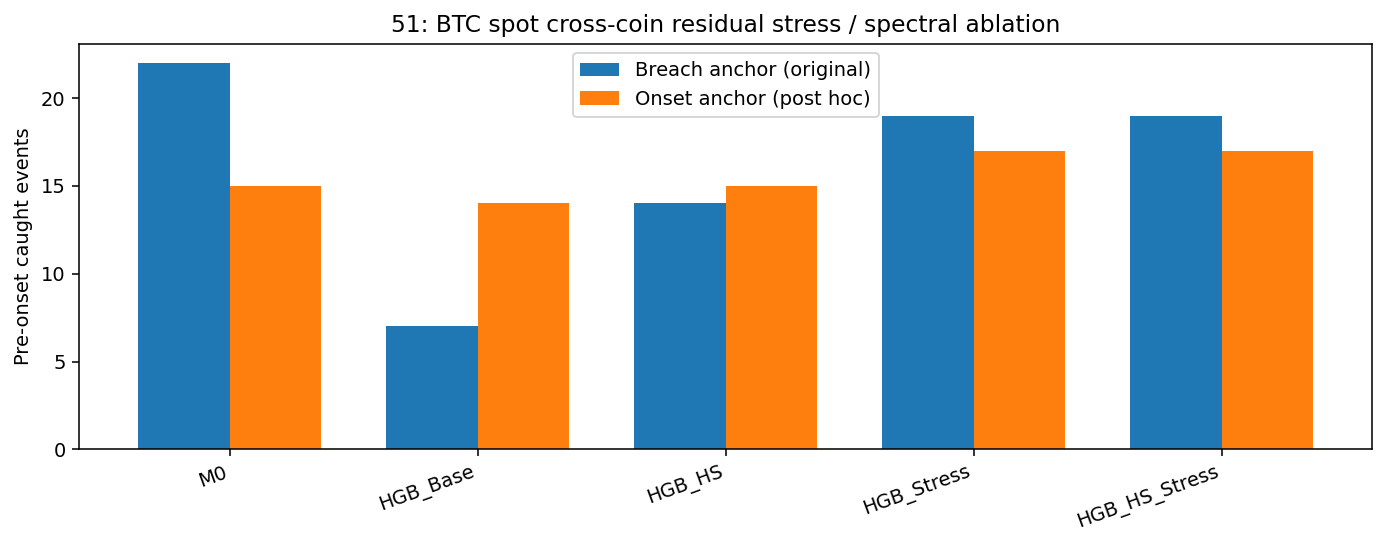

Saved all results: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/crosscoin_leading_stress_spectral_v1
Interpretation: exploratory model development, not performance confirmation.


In [11]:
MONTHLY=[]
for name,alerts in ALERTS.items():
    dt=pd.to_datetime(alerts,utc=True)
    for mo in pd.period_range('2023-01','2026-04',freq='M'):
        yy,mm=mo.year,mo.month
        sel=(dt.year==yy)&(dt.month==mm)
        tt=dt[sel]
        MONTHLY.append({'model':name,'month':str(mo),'alerts':int(sel.sum()),
                        'first_half':int(np.sum(tt.day<=15)),
                        'second_half':int(np.sum(tt.day>15)),
                        'last_day':int(tt.day.max()) if len(tt) else np.nan})
MONTHLY=pd.DataFrame(MONTHLY)
MONTHLY.to_csv(OUT/'51_6_monthly_alert_use.csv',index=False)
YRS=[]
for h in (240,1440):
    for anchor in ('breach','onset'):
        events=EVAL[h] if anchor=='breach' else EVAL_ON[h]
        years=events.onset_1pct_utc.dt.year.to_numpy()
        for name in FEATURES:
            hits=HITS[(h,anchor,name)].hit.to_numpy(bool)
            for yr in (2023,2024,2025,2026):
                idx=years==yr
                tt=pd.to_datetime(ALERTS[name],utc=True)
                count=int(np.sum(tt.year==yr))
                YRS.append({'H':h,'anchor':anchor,'model':name,'year':yr,
                            'events':int(idx.sum()),'hits':int(hits[idx].sum()),
                            'annual_alerts':count})
pd.DataFrame(YRS).to_csv(OUT/'51_7_year_descriptive.csv',index=False)

PRIMARY=EVENT_RESULTS.query('H==240 and anchor=="onset"').copy()
ORIGINAL=EVENT_RESULTS.query('H==240 and anchor=="breach"').copy()
ONE=AUC_DF.query('H==240').set_index('model')
PAIR51=[]
for base,new in PAIR_NAMES:
    ar=PRIMARY[PRIMARY.model==base].iloc[0]
    br=PRIMARY[PRIMARY.model==new].iloc[0]
    an=ONE.loc[base];bn=ONE.loc[new]
    ob=ORIGINAL[ORIGINAL.model==base].iloc[0]
    on=ORIGINAL[ORIGINAL.model==new].iloc[0]
    PAIR51.append({'baseline':base,'candidate':new,
        'delta_onset_catches':int(br.pre_catches-ar.pre_catches),
        'delta_breach_catches':int(on.pre_catches-ob.pre_catches),
        'delta_within_RV_pre_AUC':float(bn.auc_pre_within_rv_decile-an.auc_pre_within_rv_decile),
        'delta_alerts':int(br.alerts-ar.alerts),
        'same_budget_within_1pct':abs(int(br.alerts-ar.alerts))<=max(1,int(.01*ar.alerts)),
        'predefined_descriptive_hurdle':bool((br.pre_catches-ar.pre_catches)>=4 and
                                      (bn.auc_pre_within_rv_decile-an.auc_pre_within_rv_decile)>=.02 and
                                      abs(int(br.alerts-ar.alerts))<=max(1,int(.01*ar.alerts))),
        'not_independent_evidence':True})
SCREEN=pd.DataFrame(PAIR51)
SCREEN.to_csv(OUT/'51_8_exploratory_screen.csv',index=False)
display(SCREEN)

fig,ax=plt.subplots(figsize=(10,4),dpi=140)
names=list(FEATURES)
bvals=[int(ORIGINAL.loc[ORIGINAL.model==n,'pre_catches'].iloc[0]) for n in names]
ovals=[int(PRIMARY.loc[PRIMARY.model==n,'pre_catches'].iloc[0]) for n in names]
xx=np.arange(len(names));ww=.37
ax.bar(xx-ww/2,bvals,width=ww,label='Breach anchor (original)')
ax.bar(xx+ww/2,ovals,width=ww,label='Onset anchor (post hoc)')
ax.set_xticks(xx,names,rotation=20,ha='right');ax.set_ylabel('Pre-onset caught events')
ax.legend();ax.set_title('51: BTC spot cross-coin residual stress / spectral ablation')
fig.tight_layout();fig.savefig(OUT/'51_figure_catches.png',dpi=160);plt.show()

summary={'status':'EXPLORATORY_POSTHOC_NOT_VALIDATION',
         'original_47_reproduction':P_ORIG,
         'source_sha256':source_manifest,
         'common_support':COV_SUM,
         '2021_residual_fit':betas,
         'fair_train_size':int(TRAIN_C.sum()),'train_positive':int(y.sum()),
         'calibration_alerts':N_CAL,
         'development_alerts':{k:len(v) for k,v in ALERTS.items()},
         'four_hour_onset_results':PRIMARY.to_dict('records'),
         'four_hour_original_breach_results':ORIGINAL.to_dict('records'),
         'four_hour_auc':AUC_DF.query('H==240').to_dict('records'),
         'exploratory_comparisons':PAIR51,
         'important_notes':[
             'No unused BTC events or independent holdout; development sample repeatedly inspected.',
             'Onset endpoint selected as a research objective after viewing previous results.',
             'Cross-coin residuals estimated from contemporaneous historical 2021 alt and BTC returns, but all forecast features use t-75 to t-15.',
             'For fair comparisons all predictors were fit on identical common-support rows; therefore do NOT compare common-support counts directly with original 47 22/13/12 reproduction.',
             'The no-future-input test establishes a coding contract, not econometric causality.',
             'Previously negative notebook 47 primary screen is unchanged; pre-registered Dec 2026–Nov 2027 test untouched.'
         ]}
(OUT/'51_SUMMARY.json').write_text(json.dumps(summary,indent=2,default=float))
print('Saved all results:',OUT)
print('Interpretation: exploratory model development, not performance confirmation.')

## Interpretation
`51_1_common_support.csv` describes the common support. I do not expect catch counts on it to equal the notebook 47 counts, because common support can remove scoreable minutes. `51_2_all_models_event_results.csv` holds both 4-hour windows and the 24-hour checks, and `51_8_exploratory_screen.csv` isolates stress added to Base, stress added to HS, and HS added to stress; differences in 2023–2026 may still reflect data snooping. Paired event disagreement is more informative than aggregate hits, and I never count more alerts as better performance without the budget audit. The fitted spectral × stress interactions in `HGB_HS_Stress` do not establish causal leadership.